# Customer Segmentation Using K-Means Clustering

## InternAlpha Data Analytics Internship — Task 2

### Objective

The objective of this project is to segment customers based on their demographic characteristics and purchasing behavior using the K-Means clustering algorithm.

Customer segmentation allows businesses to identify groups of customers with similar characteristics and spending patterns. These segments can help businesses develop targeted marketing strategies, improve customer engagement, and make data-driven decisions.

### Dataset

The dataset contains information about 200 customers, including:

- Customer ID
- Gender
- Age
- Annual Income
- Spending Score

### Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn

### Methodology

1. Load and inspect the dataset
2. Perform data quality checks
3. Conduct exploratory data analysis
4. Select relevant features
5. Standardize the features
6. Determine the optimal number of clusters
7. Apply K-Means clustering
8. Visualize customer segments
9. Analyze cluster characteristics
10. Generate business insights and recommendations

## 1. Import Required Libraries

The following libraries are used throughout the analysis:

- **Pandas** for data manipulation and analysis
- **NumPy** for numerical operations
- **Matplotlib** for data visualization
- **Scikit-learn** for feature scaling, K-Means clustering, and model evaluation


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

%matplotlib inline

In [42]:
import os

output_dir = "../outputs"
os.makedirs(output_dir, exist_ok=True)

print(f"Output directory ready: {output_dir}")

Output directory ready: ../outputs


## 2. Load the Dataset

The customer dataset is loaded into a Pandas DataFrame.

The dataset is stored in the project's `data` directory.


In [6]:
file_path = "../data/Mall_Customers.csv"

df = pd.read_csv(file_path)

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Initial Dataset Inspection

Before performing any analysis, we inspect the structure of the dataset.

This includes checking:

- Number of rows and columns
- Column names
- Data types
- Sample records

In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data Types:
CustomerID                int64
Genre                       str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [8]:
df.head(10)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


## 4. Statistical Summary

The `describe()` function provides statistical information about the numerical variables.

This includes the count, mean, standard deviation, minimum, maximum, and quartile values.

In [9]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 5. Data Quality Check

Before applying clustering algorithms, the dataset is checked for missing values and duplicate records.

Clean data is important because missing or duplicated observations can affect the clustering results.

In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0


## 6. Customer Demographic Overview

The dataset contains 200 unique customers.

The `CustomerID` column is an identifier and therefore does not provide meaningful information for customer segmentation.

The `Genre` column represents customer gender, while `Age`, `Annual Income (k$)`, and `Spending Score (1-100)` represent numerical customer characteristics.

In [11]:
print("Number of Customers:", df["CustomerID"].nunique())

print("\nGender Distribution:")
print(df["Genre"].value_counts())

print("\nAge Range:")
print("Minimum Age:", df["Age"].min())
print("Maximum Age:", df["Age"].max())

print("\nAnnual Income Range:")
print("Minimum Income:", df["Annual Income (k$)"].min(), "k$")
print("Maximum Income:", df["Annual Income (k$)"].max(), "k$")

print("\nSpending Score Range:")
print("Minimum Score:", df["Spending Score (1-100)"].min())
print("Maximum Score:", df["Spending Score (1-100)"].max())

Number of Customers: 200

Gender Distribution:
Genre
Female    112
Male       88
Name: count, dtype: int64

Age Range:
Minimum Age: 18
Maximum Age: 70

Annual Income Range:
Minimum Income: 15 k$
Maximum Income: 137 k$

Spending Score Range:
Minimum Score: 1
Maximum Score: 99


# Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand customer demographics, income levels, and spending behavior before applying the clustering algorithm.

## 7. Gender Distribution

The distribution of customers by gender is visualized to understand the demographic composition of the dataset.

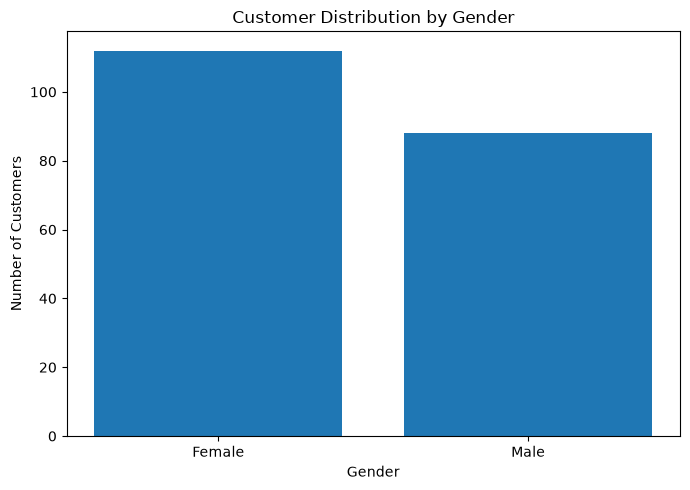

In [43]:
gender_counts = df["Genre"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(gender_counts.index, gender_counts.values)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/gender_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Age Distribution

The age distribution helps us understand the demographic spread of customers in the dataset.

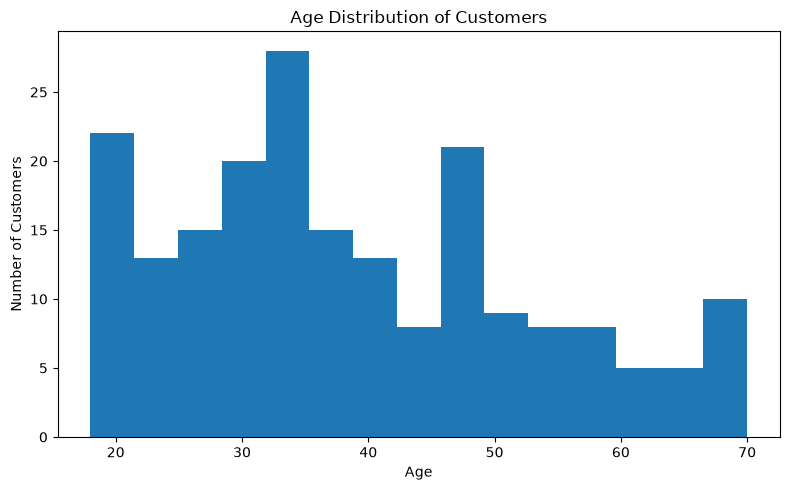

In [44]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=15)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Annual Income Distribution

Annual income is an important factor in understanding customers' purchasing capacity.

The distribution of annual income is visualized below.

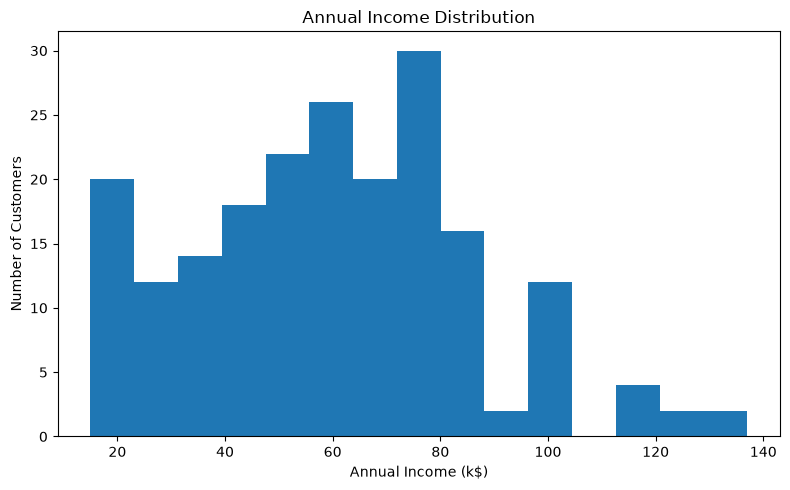

In [45]:
plt.figure(figsize=(8, 5))

plt.hist(df["Annual Income (k$)"], bins=15)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/income_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Spending Score Distribution

The spending score represents the customer's purchasing behavior, where higher values indicate a higher spending tendency.

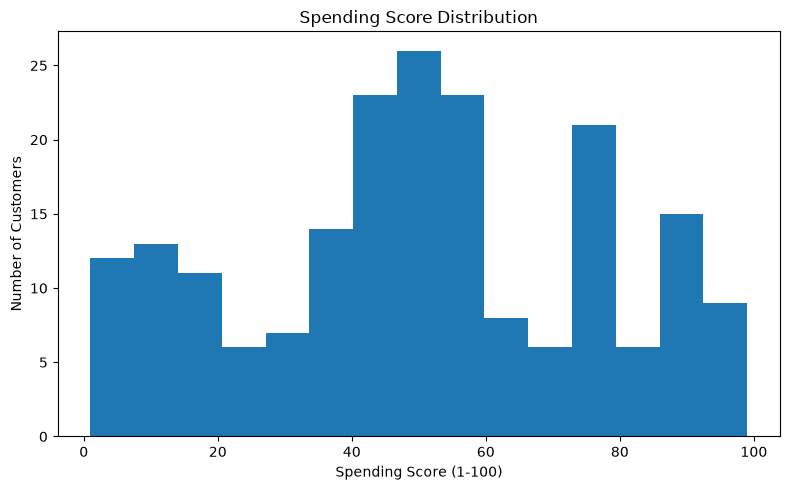

In [46]:
plt.figure(figsize=(8, 5))

plt.hist(df["Spending Score (1-100)"], bins=15)

plt.title("Spending Score Distribution")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/spending_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Age vs Annual Income

The relationship between customer age and annual income is visualized to identify potential patterns in the customer population.

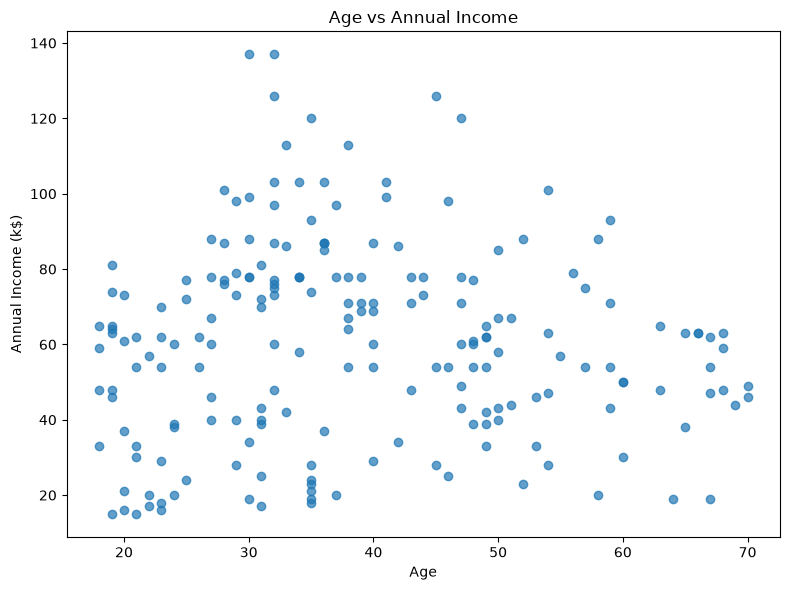

In [47]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Age"],
    df["Annual Income (k$)"],
    alpha=0.7
)

plt.title("Age vs Annual Income")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")

plt.tight_layout()

plt.savefig(
    "../outputs/age_vs_income.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Annual Income vs Spending Score

Annual income and spending score are particularly useful for customer segmentation.

Visualizing these two variables allows us to observe whether customers naturally form groups based on their income and spending behavior.

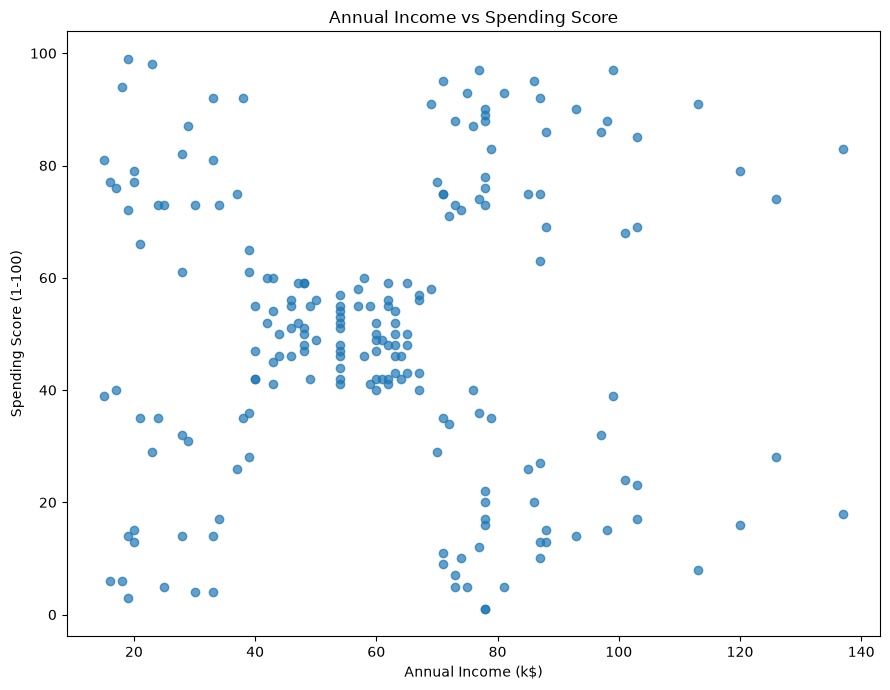

In [48]:
plt.figure(figsize=(9, 7))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.7
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.tight_layout()

plt.savefig(
    "../outputs/income_vs_spending.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 13. Correlation Analysis

Correlation analysis is used to examine the linear relationships between numerical customer attributes.

Customer ID is excluded because it is only an identifier.

In [50]:
numerical_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

correlation_matrix = df[numerical_features].corr()

correlation_matrix

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000000,-0.012398,-0.327227
Annual Income (k$),-0.012398,1.000000,0.009903
Spending Score (1-100),-0.327227,0.009903,1.000000


## 14. Correlation Visualization

The correlation matrix is visualized using Matplotlib.

Higher positive values indicate a stronger positive relationship, while values close to zero indicate a weaker linear relationship.

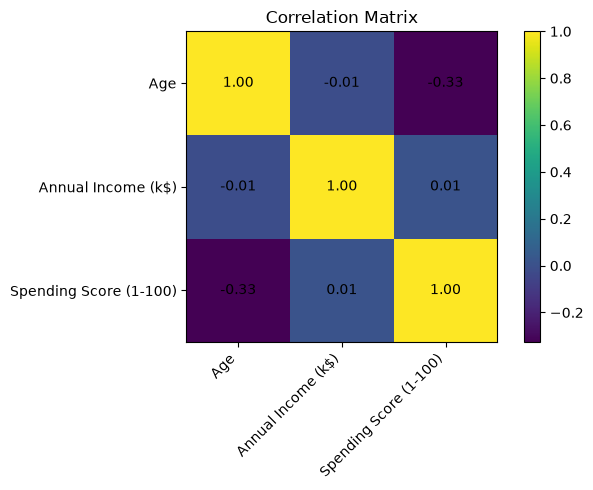

In [51]:
plt.figure(figsize=(7, 5))

plt.imshow(
    correlation_matrix,
    interpolation="nearest"
)

plt.title("Correlation Matrix")
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    "../outputs/correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Customer Segmentation Using K-Means

K-Means is an unsupervised machine learning algorithm that groups observations into a predefined number of clusters.

Each customer is assigned to the cluster whose centroid is closest to the customer's feature values.

Before applying K-Means, relevant numerical features need to be selected and standardized.

## 15. Feature Selection

For customer segmentation, we use the following features:

- Age
- Annual Income
- Spending Score

`CustomerID` is excluded because it is only an identifier.

`Genre` is also excluded from the K-Means model because it is categorical and cannot be directly used with the numerical distance calculations performed by standard K-Means.

In [20]:
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


## 16. Feature Scaling

K-Means clustering uses distance calculations. Since the selected variables have different ranges, feature scaling is performed to prevent variables with larger numerical ranges from disproportionately influencing the clustering process.

StandardScaler transforms the features so that they have approximately zero mean and unit variance.

In [21]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

X_scaled_df.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


# Determining the Optimal Number of Clusters

K-Means requires the number of clusters (`K`) to be specified before training the model.

Two evaluation techniques are used:

1. Elbow Method
2. Silhouette Score

Using both provides a stronger basis for selecting the number of clusters.

## 17. Elbow Method

The Elbow Method evaluates the within-cluster sum of squares, represented by K-Means inertia, for different values of K.

As K increases, inertia decreases. The point where the decrease begins to slow significantly is considered the elbow and provides an indication of a suitable number of clusters.

In [22]:
inertia_values = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    
    inertia_values.append(kmeans.inertia_)

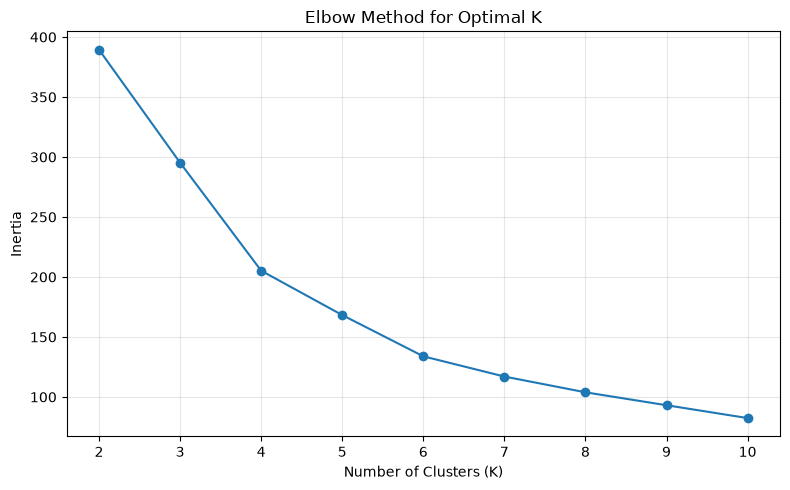

In [52]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(list(k_values))

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../outputs/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 18. Silhouette Score

The Silhouette Score measures how similar each observation is to its own cluster compared with other clusters.

The score ranges from -1 to 1:

- Higher values generally indicate better-defined clusters.
- Values close to 0 indicate overlapping clusters.
- Negative values may indicate that observations have been assigned to inappropriate clusters.

We calculate the score for several possible values of K.

In [54]:
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, cluster_labels)
    
    silhouette_scores.append(score)

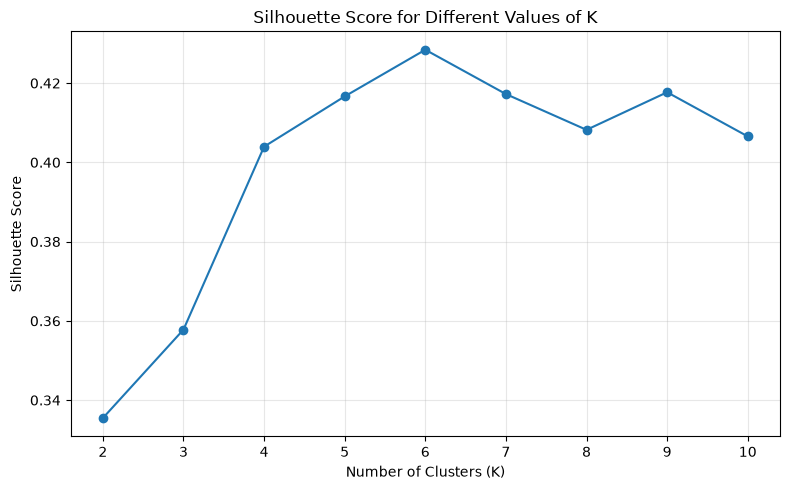

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different Values of K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.xticks(list(k_values))

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../outputs/silhouette_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
silhouette_results = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Silhouette Score": silhouette_scores
})

silhouette_results

,Number of Clusters,Silhouette Score
0,2,0.335472
1,3,0.357793
2,4,0.403958
3,5,0.416643
4,6,0.428417
5,7,0.417232
6,8,0.408207
7,9,0.417693
8,10,0.406554


## 19. Selecting the Number of Clusters

The Elbow Method and Silhouette Score are considered together to select an appropriate number of clusters.

The final value of K should provide a reasonable balance between compact clusters and meaningful customer segments.

In [27]:
best_k_by_silhouette = list(k_values)[np.argmax(silhouette_scores)]

best_silhouette_score = max(silhouette_scores)

print("Best K according to Silhouette Score:", best_k_by_silhouette)
print("Highest Silhouette Score:", round(best_silhouette_score, 4))

Best K according to Silhouette Score: 6
Highest Silhouette Score: 0.4284


# Building the K-Means Clustering Model

The K-Means model is now trained using the selected number of clusters.

Each customer will receive a cluster label representing the customer segment to which they belong.

In [28]:
optimal_k = best_k_by_silhouette

kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

df["Cluster"] = cluster_labels

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,4
2,3,Female,20,16,6,5
3,4,Female,23,16,77,4
4,5,Female,31,17,40,5


In [59]:
cluster_names = {
    0: "Mature Moderate Spenders",
    1: "Young Moderate Spenders",
    2: "High-Income Low Spenders",
    3: "High-Income High Spenders",
    4: "Low-Income High Spenders",
    5: "Low-Income Low Spenders"
}

df["Segment"] = df["Cluster"].map(cluster_names)

print("Customer segment names assigned successfully.")

Customer segment names assigned successfully.


## 20. Number of Customers in Each Cluster

The number of customers assigned to each cluster is calculated to understand the size of each customer segment.

In [29]:
cluster_counts = df["Cluster"].value_counts().sort_index()

cluster_counts

Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

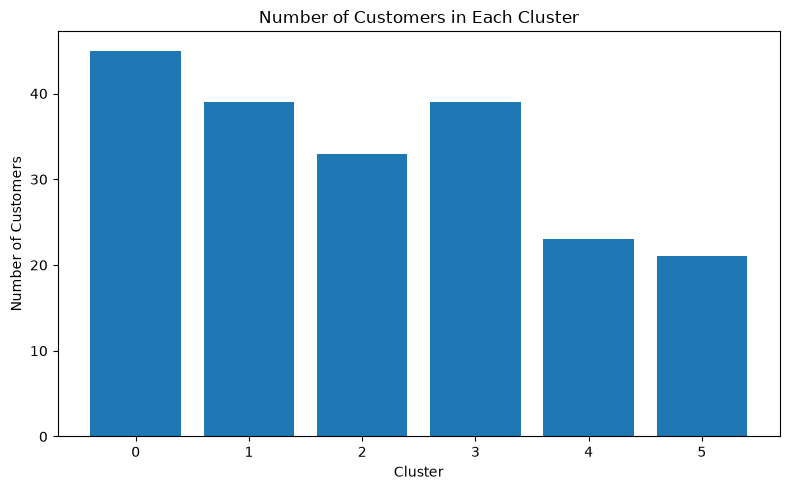

In [56]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../outputs/cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Customer Cluster Visualization

The customer clusters are visualized using Annual Income and Spending Score.

These two variables provide an intuitive representation of purchasing capacity and spending behavior.

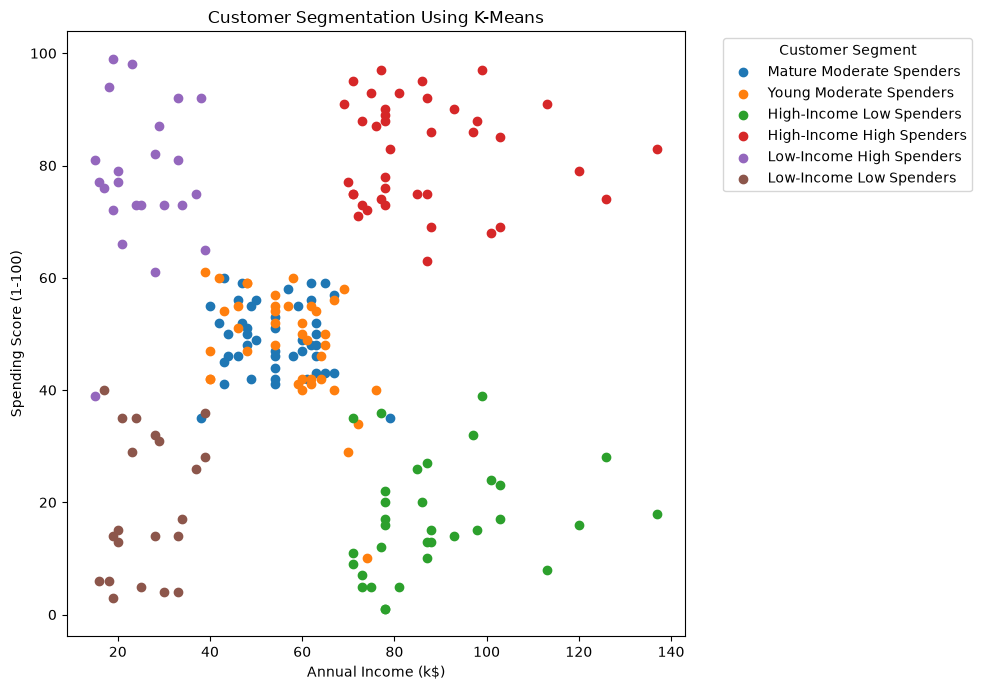

In [57]:
plt.figure(figsize=(10, 7))

for cluster in sorted(df["Cluster"].unique()):
    
    cluster_data = df[df["Cluster"] == cluster]
    
    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=cluster_names[cluster]
    )

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(
    title="Customer Segment",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "../outputs/customer_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 21. Cluster Centroids

The K-Means algorithm calculates a centroid for each cluster.

The centroids represent the average standardized feature values of customers belonging to each segment.

In [32]:
centroids_scaled = kmeans_final.cluster_centers_

centroids_original = scaler.inverse_transform(centroids_scaled)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=features
)

centroid_df.index.name = "Cluster"

centroid_df

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,56.333333,54.266667,49.066667
1,26.794872,57.102564,48.128205
2,41.939394,88.939394,16.969697
3,32.692308,86.538462,82.128205
4,25.000000,25.260870,77.608696
5,45.523810,26.285714,19.380952


# Cluster Profiling

To understand the characteristics of each customer segment, we calculate the average age, annual income, and spending score for every cluster.

This allows us to translate the mathematical clusters into meaningful customer profiles.

In [33]:
cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_profile

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38


## 21. Cluster Profile Visualization

The average annual income and spending score of each customer segment are visualized below.

This comparison helps identify differences in purchasing capacity and spending behavior across the six clusters.

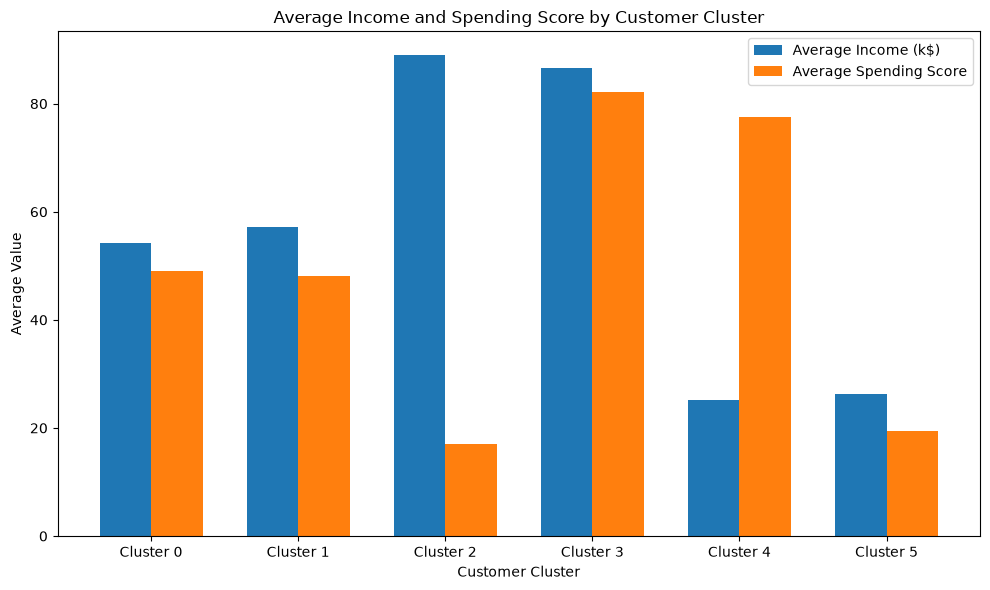

In [58]:
plt.figure(figsize=(10, 6))

x = np.arange(len(cluster_profile))
width = 0.35

plt.bar(
    x - width / 2,
    cluster_profile["Average_Income"],
    width,
    label="Average Income (k$)"
)

plt.bar(
    x + width / 2,
    cluster_profile["Average_Spending_Score"],
    width,
    label="Average Spending Score"
)

plt.title("Average Income and Spending Score by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Value")

plt.xticks(
    x,
    [f"Cluster {i}" for i in cluster_profile.index]
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "../outputs/cluster_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Customer Segment Interpretation

The clusters are interpreted based on their average age, annual income, and spending score.

The interpretation is data-driven and should be based on the calculated cluster profiles rather than assuming predefined customer categories.

In [39]:
cluster_names = {
    0: "Mature Moderate Spenders",
    1: "Young Moderate Spenders",
    2: "High-Income Low Spenders",
    3: "High-Income High Spenders",
    4: "Low-Income High Spenders",
    5: "Low-Income Low Spenders"
}

df["Segment"] = df["Cluster"].map(cluster_names)

cluster_profile_named = cluster_profile.copy()

cluster_profile_named["Segment"] = cluster_profile_named.index.map(cluster_names)

cluster_profile_named = cluster_profile_named[
    [
        "Segment",
        "Customer_Count",
        "Average_Age",
        "Average_Income",
        "Average_Spending_Score"
    ]
]

cluster_profile_named

,Segment,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,,
0,Mature Moderate Spenders,45,56.33,54.27,49.07
1,Young Moderate Spenders,39,26.79,57.10,48.13
2,High-Income Low Spenders,33,41.94,88.94,16.97
3,High-Income High Spenders,39,32.69,86.54,82.13
4,Low-Income High Spenders,23,25.00,25.26,77.61
5,Low-Income Low Spenders,21,45.52,26.29,19.38


## 23. Detailed Customer Segment Analysis

The six customer segments identified by the K-Means model are described below.

### 1. Mature Moderate Spenders
These customers have the highest average age among the segments, with moderate annual income and spending scores. They represent a relatively large customer group and may respond well to products and services focused on reliability, convenience, and long-term value.

### 2. Young Moderate Spenders
This group consists primarily of younger customers with moderate income and spending behavior. Targeted promotions, digital campaigns, and products designed for younger consumers may help increase their engagement.

### 3. High-Income Low Spenders
These customers have high average annual income but a relatively low spending score. They represent an opportunity for the business because their purchasing capacity is high, but their current engagement is relatively low.

### 4. High-Income High Spenders
This is the most attractive segment from a purchasing perspective. Customers have both high average income and high spending scores, making them strong candidates for premium products, personalized offers, and loyalty programs.

### 5. Low-Income High Spenders
These customers have relatively low average income but a high spending score. They demonstrate strong purchasing engagement despite lower income and may respond well to value-oriented products, promotions, and loyalty incentives.

### 6. Low-Income Low Spenders
This group has both relatively low income and low spending scores. Marketing resources for this segment should focus on cost-effective engagement and targeted promotions.

## 24. Customer Segment Summary

The following table provides a concise summary of the identified customer segments.

In [40]:
segment_summary = pd.DataFrame({
    "Cluster": cluster_profile_named.index,
    "Segment": cluster_profile_named["Segment"].values,
    "Customers": cluster_profile_named["Customer_Count"].values,
    "Average Age": cluster_profile_named["Average_Age"].values,
    "Average Income (k$)": cluster_profile_named["Average_Income"].values,
    "Average Spending Score": cluster_profile_named["Average_Spending_Score"].values
})

segment_summary

,Cluster,Segment,Customers,Average Age,Average Income (k$),Average Spending Score
0,0,Mature Moderate Spenders,45,56.33,54.27,49.07
1,1,Young Moderate Spenders,39,26.79,57.10,48.13
2,2,High-Income Low Spenders,33,41.94,88.94,16.97
3,3,High-Income High Spenders,39,32.69,86.54,82.13
4,4,Low-Income High Spenders,23,25.00,25.26,77.61
5,5,Low-Income Low Spenders,21,45.52,26.29,19.38


## 23. Identify High-Value Customer Segments

A high-value customer segment can generally be characterized by a relatively high annual income combined with a relatively high spending score.

The cluster profile is used to identify the segment with the strongest combination of these characteristics.

In [36]:
cluster_profile["Value_Index"] = (
    cluster_profile["Average_Income"]
    * cluster_profile["Average_Spending_Score"]
)

high_value_cluster = cluster_profile["Value_Index"].idxmax()

print("Potential High-Value Customer Cluster:", high_value_cluster)

print("\nProfile:")
print(cluster_profile.loc[high_value_cluster])

Potential High-Value Customer Cluster: 3

Profile:
Customer_Count              39.0000
Average_Age                 32.6900
Average_Income              86.5400
Average_Spending_Score      82.1300
Value_Index               7107.5302
Name: 3, dtype: float64


# Business Insights and Recommendations

The clustering results can be translated into actionable business strategies.

Different customer segments may respond differently to marketing campaigns, promotions, and customer retention strategies.

The following recommendations are based on the characteristics observed in the generated clusters.

In [37]:
income_median = cluster_profile["Average_Income"].median()
spending_median = cluster_profile["Average_Spending_Score"].median()

for cluster in cluster_profile.index:
    
    income = cluster_profile.loc[cluster, "Average_Income"]
    spending = cluster_profile.loc[cluster, "Average_Spending_Score"]
    
    print(f"\nCluster {cluster}:")
    
    if income >= income_median and spending >= spending_median:
        print("Profile: High-income, high-spending customers")
        print("Recommendation: Focus on premium products, loyalty programs, and personalized offers.")
        
    elif income >= income_median and spending < spending_median:
        print("Profile: Higher-income, lower-spending customers")
        print("Recommendation: Use personalized promotions and targeted campaigns to increase engagement.")
        
    elif income < income_median and spending >= spending_median:
        print("Profile: Lower-income, high-spending customers")
        print("Recommendation: Promote value-oriented offers, bundles, and loyalty incentives.")
        
    else:
        print("Profile: Lower-income, lower-spending customers")
        print("Recommendation: Use cost-effective promotions and engagement campaigns.")


Cluster 0:
Profile: Lower-income, high-spending customers
Recommendation: Promote value-oriented offers, bundles, and loyalty incentives.

Cluster 1:
Profile: Higher-income, lower-spending customers
Recommendation: Use personalized promotions and targeted campaigns to increase engagement.

Cluster 2:
Profile: Higher-income, lower-spending customers
Recommendation: Use personalized promotions and targeted campaigns to increase engagement.

Cluster 3:
Profile: High-income, high-spending customers
Recommendation: Focus on premium products, loyalty programs, and personalized offers.

Cluster 4:
Profile: Lower-income, high-spending customers
Recommendation: Promote value-oriented offers, bundles, and loyalty incentives.

Cluster 5:
Profile: Lower-income, lower-spending customers
Recommendation: Use cost-effective promotions and engagement campaigns.


# Key Findings

The K-Means clustering analysis provides several useful insights into customer behavior:

1. Customers can be grouped into distinct segments based on age, annual income, and spending score.
2. Annual income and spending score provide useful information for distinguishing customer purchasing patterns.
3. The Elbow Method and Silhouette Score help determine an appropriate number of customer segments.
4. Cluster profiling makes it possible to understand the demographic and purchasing characteristics of each segment.
5. Different customer groups can be targeted with different marketing and engagement strategies.

## 25. Recommended Marketing Strategies

| Customer Segment | Recommended Strategy |
|---|---|
| High-Income High Spenders | Premium products, VIP programs, personalized recommendations |
| High-Income Low Spenders | Personalized promotions, targeted recommendations, re-engagement campaigns |
| Low-Income High Spenders | Discounts, bundles, loyalty rewards, value-focused offers |
| Low-Income Low Spenders | Cost-effective promotions and selective engagement |
| Young Moderate Spenders | Digital campaigns, trend-focused products, introductory offers |
| Mature Moderate Spenders | Retention programs, convenience-focused services, personalized communication |

These strategies demonstrate how clustering can support differentiated marketing decisions instead of applying the same approach to every customer.

# Final Customer Segmentation Visualization

The final visualization shows the six customer segments based on annual income and spending score.

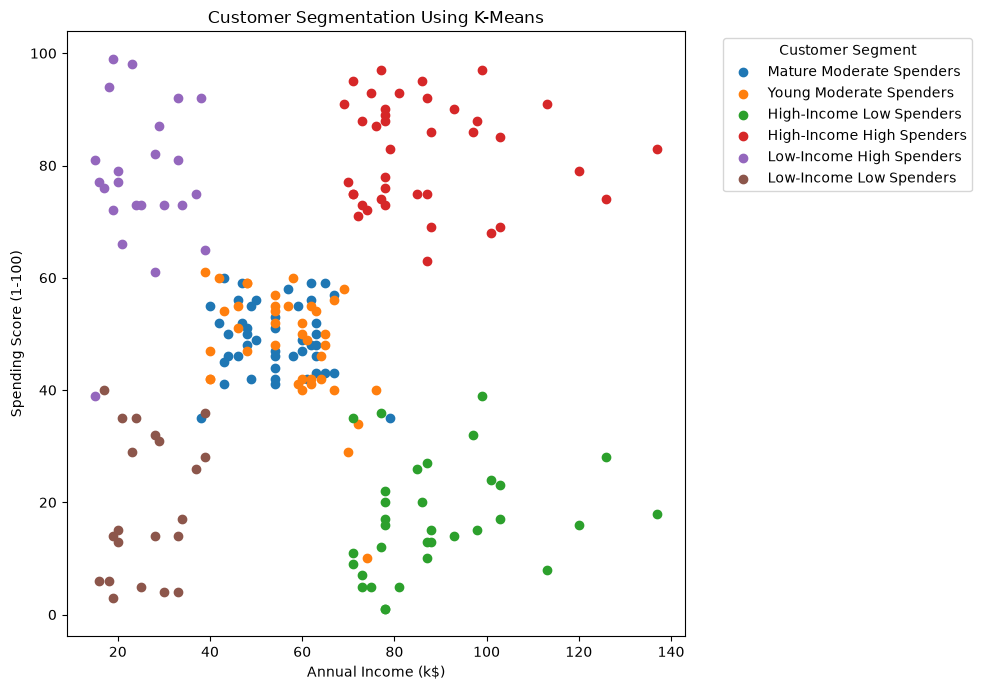

In [41]:
plt.figure(figsize=(10, 7))

for cluster in sorted(df["Cluster"].unique()):
    
    cluster_data = df[df["Cluster"] == cluster]
    
    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=cluster_names[cluster]
    )

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.legend(
    title="Customer Segment",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

# Conclusion

This project applied K-Means clustering to segment customers based on demographic and purchasing characteristics.

The analysis began with data inspection and exploratory analysis, followed by feature selection and standardization. The Elbow Method and Silhouette Score were then used to evaluate different numbers of clusters.

After selecting an appropriate number of clusters, K-Means was applied to assign each customer to a segment. The resulting clusters were profiled using average age, annual income, spending score, and customer count.

The segmentation provides a data-driven understanding of customer groups and can help businesses design more targeted marketing strategies, improve customer engagement, and allocate resources more effectively.

Overall, K-Means clustering demonstrates how unsupervised machine learning can be applied to transform customer data into actionable business insights.

# Final Project Summary

### Dataset
Mall Customer Segmentation Dataset

### Number of Customers
200

### Features Used for Clustering
- Age
- Annual Income (k$)
- Spending Score (1-100)

### Algorithm
K-Means Clustering

### Evaluation Methods
- Elbow Method
- Silhouette Score

### Main Outcome
The analysis included data inspection, quality checks, exploratory data analysis, feature selection, feature standardization, and evaluation of different cluster sizes using the Elbow Method and Silhouette Score.

The Silhouette Score indicated that **six clusters** provided the strongest segmentation among the tested values, with a score of approximately **0.4284**.

The final model identified six customer segments:

1. Mature Moderate Spenders
2. Young Moderate Spenders
3. High-Income Low Spenders
4. High-Income High Spenders
5. Low-Income High Spenders
6. Low-Income Low Spenders

The segmentation demonstrates that customers differ considerably in terms of income, spending behavior, and age. These differences provide opportunities for businesses to develop targeted marketing strategies rather than treating all customers uniformly.

The High-Income High-Spending segment represents a particularly valuable customer group, while the High-Income Low-Spending segment provides an opportunity for targeted customer engagement. Low-income segments can be approached with value-oriented strategies, while age-specific approaches can be used for younger and more mature customers.

Overall, K-Means clustering successfully transformed the customer dataset into actionable customer segments that can support data-driven marketing and customer relationship strategies. 

# Project Summary

| Component | Details |
|---|---|
| Dataset | Mall Customer Segmentation Data |
| Total Customers | 200 |
| Clustering Algorithm | K-Means |
| Features Used | Age, Annual Income, Spending Score |
| Number of Clusters | 6 |
| Silhouette Score | 0.4284 |
| Evaluation Methods | Elbow Method and Silhouette Score |
| Main Objective | Customer segmentation |